# 02 · Прогноз исхода и цена ошибки для редкого класса

При обследовании нужно выдать три вероятности — для цензурированного наблюдения (`C`), трансплантации (`CL`) и смерти (`D`). Билирубин, медь и признаки осмотра уже показали связь с исходом в `01_merged_eda.ipynb`. Здесь проверяем, удаётся ли превратить эту связь в прогноз на новых записях и помогает ли для этого чаще показывать модели редкий класс.

Маршрут исследования идёт от прогноза по частотам к логистической регрессии, затем к изменению признаков и состава обучения, градиентному бустингу и выбору порога для `CL`.

## 1. Как сравнивать прогнозы

### 1.1. Разработка, пять фолдов и итоговый контроль

Модель видит 17 признаков, доступных при обследовании. Одинаковые профили, включая возраст в исходной точности, остаются вместе. Сначала фиксируем примерно 20% размеченных строк для контроля, затем делим оставшиеся на пять фолдов. Каждый кандидат обучается и проверяется на одних и тех же разбиениях. Стратификация с групповым ограничением приближённая, поэтому ниже показано фактическое число примеров каждого класса.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import Markdown, display
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as SamplingPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, log_loss, precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder, RobustScaler,
                                   SplineTransformer, StandardScaler)
from threadpoolctl import threadpool_limits

from study_data import CATEGORICAL, CLASSES, COLORS, LABS, LOG_LABS, PROFILE, SEED, partition, profile_ids, read_inputs

plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "font.size": 10})
optuna.logging.set_verbosity(optuna.logging.WARNING)
cpu_limit = threadpool_limits(limits=1)
train, test, template = read_inputs()
dev, control, folds = partition(train)
X, y = dev[PROFILE], dev.Status
labels = np.array(CLASSES)
cl_index = CLASSES.index("CL")
groups = profile_ids(dev)
fold_rows = []
for k, (fit, val) in enumerate(folds, 1):
    counts = y.iloc[val].value_counts().reindex(CLASSES)
    fold_rows.append([len(fit), len(val), *counts, len(set(groups[fit]) & set(groups[val]))])
fold_table = pd.DataFrame(fold_rows, index=range(1,6), columns=["обучение","проверка",*CLASSES,"общих профилей"])
display(fold_table.rename_axis("фолд"))
print(f"Разработка {len(dev)} · контроль {len(control)} · конкурсный test {len(test)}.")

,обучение,проверка,C,CL,D,общих профилей
фолд,,,,,,
1,5059,1265,794,44,427,0
2,5059,1265,795,44,426,0
3,5059,1265,795,44,426,0
4,5059,1265,794,44,427,0
5,5060,1264,794,44,426,0


Разработка 6324 · контроль 1581 · конкурсный test 5271.


### 1.2. Что считаем удачным прогнозом

Основная метрика — **multiclass log loss**. Для каждой записи берём минус логарифм вероятности её истинного класса и усредняем по строкам. Ошибка с высокой уверенностью стоит дороже. Например, вероятности 0,01 и 0,25 для фактического исхода дают штрафы 4,61 и 1,39. Для отбора модели берём наименьший средний log loss пяти фолдов. Рядом показываем выборочное стандартное отклонение (SD) между ними.

Для `CL` нужны и другие ракурсы. **Полнота** показывает, какую долю трансплантаций нашли. **Точность** — какая доля помеченных моделью записей действительно относится к `CL`. **Average precision (AP)** оценивает ранжирование по вероятности `CL` при разных порогах, а **macro-F1** даёт каждому из трёх классов одинаковый вес в сводке. По умолчанию метка — класс с наибольшей вероятностью.

In [2]:
def decisions(probabilities, threshold=None):
    if threshold is None:
        return labels[probabilities.argmax(axis=1)]
    others = [CLASSES.index("C"), CLASSES.index("D")]
    fallback = labels[others][probabilities[:, others].argmax(axis=1)]
    return np.where(probabilities[:, cl_index] >= threshold, "CL", fallback)

def metrics(actual, probabilities, predicted=None):
    assert probabilities.shape == (len(actual), len(CLASSES))
    assert np.isfinite(probabilities).all() and (probabilities >= 0).all()
    assert np.allclose(probabilities.sum(axis=1), 1)
    if predicted is None:
        predicted = decisions(probabilities)
    is_cl, found_cl = np.asarray(actual) == "CL", predicted == "CL"
    return {
        "log loss": log_loss(actual, probabilities, labels=CLASSES),
        "macro-F1": f1_score(actual, predicted, labels=CLASSES, average="macro", zero_division=0),
        "полнота CL": recall_score(is_cl, found_cl, zero_division=0),
        "точность CL": precision_score(is_cl, found_cl, zero_division=0),
        "AP CL": average_precision_score(is_cl, probabilities[:, cl_index]),
        "средняя P(CL)": probabilities[:, cl_index].mean(),
    }

def coefficient_stats(model, fit_x):
    estimator = model.named_steps["model"]
    beta = estimator.coef_
    names = model.named_steps["pre"].get_feature_names_out()
    matrix = model[:-2].transform(fit_x)
    col = list(names).index("Bilirubin")
    spread = np.subtract(*np.quantile(matrix[:, col], [.75, .25]))
    gap = beta[CLASSES.index("D"), col] - beta[CLASSES.index("C"), col]
    return {"число β": beta.size, "|β| > 1e-8": (np.abs(beta) > 1e-8).sum(),
            "медиана |β|": np.median(np.abs(beta)), "макс. |β|": np.abs(beta).max(),
            "Δ log(P(D)/P(C)) за IQR билирубина": gap * spread}

def evaluate(estimator, frame, with_coefs=False):
    predictions = np.full((len(y), len(CLASSES)), np.nan)
    rows, coefs = [], []
    for fit, val in folds:
        model = clone(estimator).fit(frame.iloc[fit], y.iloc[fit])
        assert list(model.classes_) == CLASSES
        p = model.predict_proba(frame.iloc[val])
        predictions[val] = p
        rows.append(metrics(y.iloc[val], p))
        if with_coefs:
            coefs.append(coefficient_stats(model, frame.iloc[fit]))
    assert np.isfinite(predictions).all()
    return {"folds": pd.DataFrame(rows, index=range(1,6)), "oof": predictions,
            "coefs": pd.DataFrame(coefs)}

results, candidates = {}, {}
def run(name, estimator, with_coefs=False):
    candidates[name] = estimator
    results[name] = evaluate(estimator, X, with_coefs)
    return name

def summary(names):
    rows = {}
    for name in names:
        per_fold = results[name]["folds"]
        row = per_fold.mean().to_dict()
        row["SD log loss"] = per_fold["log loss"].std()
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")[
        ["log loss","SD log loss","macro-F1","полнота CL","точность CL","AP CL","средняя P(CL)"]]

def best(names):
    return summary(names)["log loss"].idxmin()

### 1.3. Отправная точка по частотам

`DummyClassifier` присваивает всем проверочным строкам одни и те же вероятности, равные долям классов в обучающем фолде. У пяти фолдов будут немного разные отправные точки. OOF (out-of-fold) — прогнозы, собранные для каждой строки разработки в тот момент, когда эта строка была на проверке.

In [23]:
dummy = run("Частоты классов", DummyClassifier(strategy="prior", random_state=SEED))
display(results[dummy]["folds"].rename_axis("фолд").round(4))
baseline_loss = summary([dummy]).loc[dummy, "log loss"]
display(Markdown(f"В среднем по фолдам частоты дают **{baseline_loss:.4f}**. При выборе максимума "
                 "этот способ предсказывает всем C. При отсутствии пометок CL в сравнительных таблицах "
                 "точность CL по принятому соглашению равна нулю."))

,log loss,macro-F1,полнота CL,точность CL,AP CL,средняя P(CL)
фолд,,,,,,
1,0.7757,0.2571,0.0,0.0,0.0348,0.0348
2,0.7753,0.2573,0.0,0.0,0.0348,0.0348
3,0.7753,0.2573,0.0,0.0,0.0348,0.0348
4,0.7757,0.2571,0.0,0.0,0.0348,0.0348
5,0.7755,0.2572,0.0,0.0,0.0348,0.0348


В среднем по фолдам частоты дают **0.7755**. При выборе максимума этот способ предсказывает всем C. При отсутствии пометок CL в сравнительных таблицах точность CL по принятому соглашению равна нулю.

## 2. Какую форму связи может выучить модель

### 2.1. Преобразования внутри пайплайна

Во всех опытах переводим возраст в годы без округления. Пропуски, если они появятся, заполним медианой числового признака или наиболее частой категорией обучающего фолда. Категории кодируем индикаторами с одним опорным уровнем для каждого поля. Это относится и к `Stage` — каждая стадия может иметь свой эффект. Числовые и категориальные поля проходят разные преобразования.

Варианты заданы заранее. В одном заменяем шесть лабораторных показателей на `log1p`. В другом добавляем отношение билирубина к альбумину и произведение логарифмов билирубина и меди. Первый признак отражает сочетание повышенного билирубина с пониженным альбумином, второй позволяет эффекту одного показателя меняться с уровнем другого. Отдельный индикатор отмечает сочетание асцита и сохраняющихся отёков. В последнем варианте квадратичные сплайны для трёх показателей допускают плавные изгибы зависимости. Это вычисляемые признаки для эксперимента на данных Kaggle.

In [4]:
def feature_frame(frame, recipe, with_days):
    out = frame[PROFILE].rename(columns={"Age":"Age_years"}).copy()
    out["Age_years"] = out.Age_years / 365.25
    if recipe != "raw":
        for name in LOG_LABS:
            out[f"log_{name}"] = np.log1p(out.pop(name))
    if recipe in {"lab", "both", "splines"}:
        out["Bilirubin_to_Albumin"] = frame.Bilirubin / frame.Albumin.replace(0, np.nan)
        out["Bilirubin_x_Copper"] = out.log_Bilirubin * out.log_Copper
    if recipe in {"exam", "both", "splines"}:
        joint = frame.Ascites.eq("Y") & frame.Edema.eq("Y")
        out["Ascites_and_Edema"] = joint.astype(float).mask(frame[["Ascites","Edema"]].isna().any(axis=1))
    if with_days:
        out["N_Days"] = frame.N_Days
    return out

def triple_cl(target):
    counts = pd.Series(target).value_counts()
    return {"CL": int(min(3 * counts["CL"], counts.max()))}

def make_model(kind="linear", recipe="raw", scale="standard", balance="natural", with_days=False):
    numeric = ["Age_years", *(f"log_{name}" if recipe != "raw" and name in LOG_LABS else name for name in LABS)]
    if recipe in {"lab", "both", "splines"}:
        numeric += ["Bilirubin_to_Albumin", "Bilirubin_x_Copper"]
    if with_days:
        numeric.append("N_Days")
    scalers = {"none":"passthrough", "standard":StandardScaler(), "robust":RobustScaler(), "minmax":MinMaxScaler()}
    curve_cols = ["log_Bilirubin","log_Copper","Albumin"] if recipe == "splines" else []
    num_pipe = Pipeline([("missing",SimpleImputer(strategy="median")), ("scale",scalers[scale])])
    cat_pipe = Pipeline([("missing",SimpleImputer(strategy="most_frequent")),
                         ("encode",OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))])
    transforms = [("numbers",num_pipe,[c for c in numeric if c not in curve_cols]),
                  ("categories",cat_pipe,CATEGORICAL)]
    if curve_cols:
        curve_pipe = Pipeline([("missing",SimpleImputer(strategy="median")),
                               ("spline",SplineTransformer(n_knots=4, degree=2, knots="quantile",
                                                          include_bias=False, extrapolation="constant")),
                               ("scale",scalers[scale])])
        transforms.append(("curves",curve_pipe,curve_cols))
    if recipe in {"exam", "both", "splines"}:
        transforms.append(("joint",SimpleImputer(strategy="most_frequent"),["Ascites_and_Edema"]))
    samplers = {"natural":"passthrough", "weights":"passthrough",
                "up":RandomOverSampler(random_state=SEED),
                "up3":RandomOverSampler(sampling_strategy=triple_cl, random_state=SEED),
                "down":RandomUnderSampler(random_state=SEED)}
    if kind == "linear":
        model = LogisticRegression(solver="newton-cholesky", C=1., max_iter=100, random_state=SEED,
                                   class_weight="balanced" if balance == "weights" else None)
    else:
        model = HistGradientBoostingClassifier(max_iter=110, learning_rate=.08, max_leaf_nodes=15,
                                               l2_regularization=2., max_bins=128,
                                               early_stopping=False, random_state=SEED)
    return SamplingPipeline([
        ("features",FunctionTransformer(feature_frame, kw_args={"recipe":recipe, "with_days":with_days})),
        ("pre",ColumnTransformer(transforms, verbose_feature_names_out=False)),
        ("sample",samplers[balance]), ("model",model),
    ])

### 2.2. Что меняется от масштаба при той же регуляризации

Обычная линейная регрессия предполагает числовую цель. Здесь метки обозначают три разных события, поэтому используем многоклассовую логистическую регрессию с softmax. Она выдаёт три согласованные вероятности. L2-штраф с фиксированным `C=1` ограничивает величину коэффициентов, и смена единиц меняет силу штрафа на исходной шкале.

Сравним исходные единицы, стандартизацию (среднее и SD), устойчивое масштабирование (медиана и IQR) и приведение к диапазону 0–1. Категориальные индикаторы во всех четырёх случаях одинаковы. Для сравнения коэффициентов в сопоставимых единицах вычислим также изменение логарифма отношения вероятностей `D/C` при росте билирубина на один межквартильный размах при прочих равных.

In [5]:
scales = {"none":"Без масштабирования","standard":"StandardScaler",
          "robust":"RobustScaler","minmax":"MinMaxScaler"}
for key, name in scales.items():
    run(name, make_model(scale=key), with_coefs=True)
scale_scores = summary(scales.values())
coefs = pd.DataFrame({name: results[name]["coefs"].mean() for name in scales.values()}).T
display(scale_scores[["log loss","SD log loss"]].join(coefs).round(4))
scale_name = best(scales.values())
scale_key = next(k for k, v in scales.items() if v == scale_name)
span = scale_scores["log loss"].max() - scale_scores["log loss"].min()
display(Markdown(f"Для следующего опыта берём **{scale_name}** по среднему log loss. "
                 f"Размах между четырьмя результатами — {span:.4f}, при SD по фолдам "
                 f"{scale_scores.loc[scale_name,'SD log loss']:.4f} у выбранного варианта. На этих данных "
                 "смена единиц мало влияет на качество. Число коэффициентов одинаково, а их модуль зависит "
                 "от единицы измерения. Последний столбец показывает эффект одного и того же сдвига билирубина."))

,log loss,SD log loss,число β,|β| > 1e-8,медиана |β|,макс. |β|,Δ log(P(D)/P(C)) за IQR билирубина
Без масштабирования,0.5331,0.0148,60.0,60.0,0.1026,1.4610,0.4063
StandardScaler,0.5331,0.0148,60.0,60.0,0.1575,1.4595,0.4053
RobustScaler,0.5331,0.0148,60.0,60.0,0.1602,1.4595,0.4061
MinMaxScaler,0.5326,0.0138,60.0,60.0,0.4035,2.7032,0.3683


Для следующего опыта берём **MinMaxScaler** по среднему log loss. Размах между четырьмя результатами — 0.0005, при SD по фолдам 0.0138 у выбранного варианта. На этих данных смена единиц мало влияет на качество. Число коэффициентов одинаково, а их модуль зависит от единицы измерения. Последний столбец показывает эффект одного и того же сдвига билирубина.

### 2.3. Что добавляют логарифмы, взаимодействия и сплайны

Оставляем модель и выбранный способ масштабирования, меняем только представление признаков. Разницу с исходными значениями считаем попарно по одним и тем же фолдам. Знак минус означает снижение потери.

In [6]:
recipes = {"raw":scale_name, "log":"Логарифмы", "lab":"Логарифмы + лабораторные сочетания",
           "exam":"Логарифмы + признак осмотра", "both":"Оба набора сочетаний",
           "splines":"Сочетания + сплайны"}
for key, name in recipes.items():
    if key != "raw":
        run(name, make_model(recipe=key, scale=scale_key))
feature_scores = summary(recipes.values())
feature_scores["Δ к исходным"] = feature_scores["log loss"] - feature_scores.loc[scale_name,"log loss"]
display(feature_scores[["log loss","SD log loss","Δ к исходным","AP CL"]].round(4))
linear_name = best(recipes.values())
linear_key = next(k for k, v in recipes.items() if v == linear_name)
log_gain = feature_scores.loc[recipes["log"], "Δ к исходным"]
after_log = feature_scores.loc[linear_name, "log loss"] - feature_scores.loc[recipes["log"], "log loss"]
display(Markdown(f"Замена шести шкал на логарифмы изменила log loss на **{log_gain:+.4f}**. "
                 f"У лучшего представления, **{linear_name}**, дополнительная разница относительно одних "
                 f"логарифмов составила {after_log:+.4f}. Дальше фиксируем этот вариант для опытов с составом обучения."))

,log loss,SD log loss,Δ к исходным,AP CL
MinMaxScaler,0.5326,0.0138,0.0000,0.1162
Логарифмы,0.5189,0.0110,-0.0137,0.1230
Логарифмы + лабораторные сочетания,0.5161,0.0107,-0.0165,0.1327
Логарифмы + признак осмотра,0.5185,0.0110,-0.0141,0.1229
Оба набора сочетаний,0.5156,0.0108,-0.0169,0.1331
Сочетания + сплайны,0.5086,0.0113,-0.0240,0.1491


Замена шести шкал на логарифмы изменила log loss на **-0.0137**. У лучшего представления, **Сочетания + сплайны**, дополнительная разница относительно одних логарифмов составила -0.0103. Дальше фиксируем этот вариант для опытов с составом обучения.

### 2.4. Сколько информации добавил бы срок наблюдения

Повторяем выбранную линейную модель на тех же фолдах, разрешив ровно один дополнительный столбец — `N_Days`. Число характеризует зависимость ответа от знания будущего в этой конкретной постановке. Этот опыт ведётся отдельно от отбора итоговой модели.

In [7]:
with_time = evaluate(make_model(recipe=linear_key, scale=scale_key, with_days=True), dev[[*PROFILE,"N_Days"]])
timing = pd.DataFrame({"на момент осмотра":results[linear_name]["folds"]["log loss"],
                       "при известном сроке":with_time["folds"]["log loss"]})
timing["разница"] = timing.iloc[:,1] - timing.iloc[:,0]
display(timing.rename_axis("фолд").round(4))
display(Markdown(f"Средняя разница составила **{timing['разница'].mean():+.4f}** log loss. "
                 "Чтобы получить первый прогноз, достаточно данных обследования. Для второго пришлось "
                 "дождаться окончания наблюдения. В конкурсный файл пойдут вероятности по данным обследования."))

,на момент осмотра,при известном сроке,разница
фолд,,,
1,0.5203,0.5171,-0.0033
2,0.5214,0.5171,-0.0043
3,0.5012,0.4982,-0.0030
4,0.4994,0.4957,-0.0037
5,0.5006,0.4970,-0.0036


Средняя разница составила **-0.0036** log loss. Чтобы получить первый прогноз, достаточно данных обследования. Для второго пришлось дождаться окончания наблюдения. В конкурсный файл пойдут вероятности по данным обследования.

## 3. Помогает ли балансировка находить трансплантации

### 3.1. Что меняется в обучающем фолде

Проверим четыре способа дать редким исходам больший вес. Взвешивание меняет вклад строки в функцию потерь. Умеренный апсэмплинг утраивает число `CL`, повторяя выбранные строки. Полный апсэмплинг доводит каждый класс до численности самого частого. Полный даунсэмплинг случайно оставляет в каждом классе столько же строк, сколько их у самого редкого. Исходные записи и естественные доли проверки сохраняются. Масштабирование обучается на исходной обучающей части до сэмплинга.

In [8]:
balance_names = {"natural":"Как в данных", "weights":"Обратные частоты", "up3":"Апсэмплинг CL ×3",
                 "up":"Апсэмплинг до большинства", "down":"Даунсэмплинг до меньшинства"}
fit0, valid0 = folds[0]
raw_y = y.iloc[fit0]
audit_rows, composition = {}, {}
for mode, name in balance_names.items():
    pipe = make_model(recipe=linear_key, scale=scale_key, balance=mode)
    sampler = pipe.named_steps["sample"]
    if sampler == "passthrough":
        batch, target = X.iloc[fit0], raw_y
    else:
        batch, target = sampler.fit_resample(X.iloc[fit0], raw_y)
    counts = target.value_counts().reindex(CLASSES)
    effective_cl = 1/3 if mode == "weights" else counts.CL / counts.sum()
    audit_rows[name] = [*counts, counts.sum(), effective_cl]
    weights = target.map(1 / counts).to_numpy() if mode == "weights" else np.ones(len(batch))
    composition[name] = [np.average(values, weights=weights) for values in
                         [batch.Bilirubin, batch.Age, batch.Stage.eq(4), batch.Ascites.eq("Y")]]
valid_counts = y.iloc[valid0].value_counts().reindex(CLASSES)
audit_rows["Проверка для всех вариантов"] = [*valid_counts, valid_counts.sum(), valid_counts.CL/valid_counts.sum()]
balance_audit = pd.DataFrame.from_dict(audit_rows, orient="index",
                                      columns=[*CLASSES,"всего","доля CL с учётом весов"])
display(balance_audit.round(3))

,C,CL,D,всего,доля CL с учётом весов
Как в данных,3178,176,1705,5059,0.035
Обратные частоты,3178,176,1705,5059,0.333
Апсэмплинг CL ×3,3178,528,1705,5411,0.098
Апсэмплинг до большинства,3178,3178,3178,9534,0.333
Даунсэмплинг до меньшинства,176,176,176,528,0.333
Проверка для всех вариантов,794,44,427,1265,0.035


После апсэмплинга строк больше, но число уникальных примеров `CL` остаётся прежним. При полном даунсэмплинге сохраняются все редкие примеры и лишь малая часть двух частых классов. Сравним, оправдана ли такая потеря данных.

### 3.2. Как балансировка классов меняет состав признаков

Если трансплантации чаще встречаются при определённых результатах осмотра, увеличение частоты `CL` меняет и распределение этих результатов в обучении. На том же первом фолде сравним средние билирубина и возраста в единицах исходного стандартного отклонения, а частоты четвёртой стадии и асцита — в процентных пунктах. Для варианта с весами возьмём взвешенные средние.

In [9]:
mix = pd.DataFrame.from_dict(composition, orient="index",
                             columns=["билирубин, SD","возраст, SD","стадия 4, п.п.","асцит, п.п."])
mix = (mix - mix.loc[balance_names["natural"]]) / [X.Bilirubin.iloc[fit0].std(), X.Age.iloc[fit0].std(), .01, .01]
display(mix.round(3))
up_mix = mix.loc[balance_names["up"]]
display(Markdown(f"При полном апсэмплинге средний билирубин сдвинулся на **{up_mix.iloc[0]:+.2f} SD**, "
                 f"а доля четвёртой стадии — на **{up_mix.iloc[2]:+.1f} п.п.** относительно исходного фолда. "
                 "Поэтому изменение состава обучения проверяем на строках с естественными долями классов."))

,"билирубин, SD","возраст, SD","стадия 4, п.п.","асцит, п.п."
Как в данных,0.000,0.000,0.000,0.000
Обратные частоты,0.119,-0.124,5.632,0.454
Апсэмплинг CL ×3,0.003,-0.039,0.293,-0.147
Апсэмплинг до большинства,0.115,-0.137,5.238,0.306
Даунсэмплинг до меньшинства,0.123,-0.127,5.446,-0.467


При полном апсэмплинге средний билирубин сдвинулся на **+0.11 SD**, а доля четвёртой стадии — на **+5.2 п.п.** относительно исходного фолда. Поэтому изменение состава обучения проверяем на строках с естественными долями классов.

### 3.3. Вероятности после изменения частот

Если в обучении трансплантации встречаются втрое чаще, модель может систематически завышать их вероятность для обычного потока. Для каждого способа проверим прогноз как есть и с поправкой на частоты. Вероятность каждого класса умножаем на отношение его доли **до** балансировки к его эффективной доле **после**, затем нормируем строку до суммы 1. При обратных весах эффективные доли равны 1/3. Все доли берём только из обучающего фолда.

Эта поправка следует из формулы Байеса при сдвиге только долей классов. Повторы, регуляризация и удаление наблюдений могут влиять и на саму форму модели, поэтому эффект поправки измеряем на проверочных строках.

,log loss,SD log loss,macro-F1,полнота CL,точность CL,AP CL,средняя P(CL)
Сочетания + сплайны,0.5086,0.0113,0.5291,0.0000,0.0000,0.1491,0.0347
Обратные частоты,0.7490,0.0243,0.5518,0.5864,0.1037,0.1347,0.2537
Обратные частоты · поправка,0.5114,0.0112,0.5297,0.0000,0.0000,0.1420,0.0344
Апсэмплинг CL ×3,0.5351,0.0144,0.5662,0.0864,0.1723,0.1367,0.0891
Апсэмплинг CL ×3 · поправка,0.5095,0.0117,0.5301,0.0000,0.0000,0.1367,0.0345
Апсэмплинг до большинства,0.7505,0.0232,0.5491,0.5909,0.1018,0.1337,0.2530
Апсэмплинг до большинства · поправка,0.5127,0.0105,0.5303,0.0000,0.0000,0.1401,0.0349
Даунсэмплинг до меньшинства,0.7883,0.0280,0.5326,0.5818,0.0941,0.1267,0.2673
Даунсэмплинг до меньшинства · поправка,0.5325,0.0177,0.5255,0.0045,0.2000,0.1283,0.0357


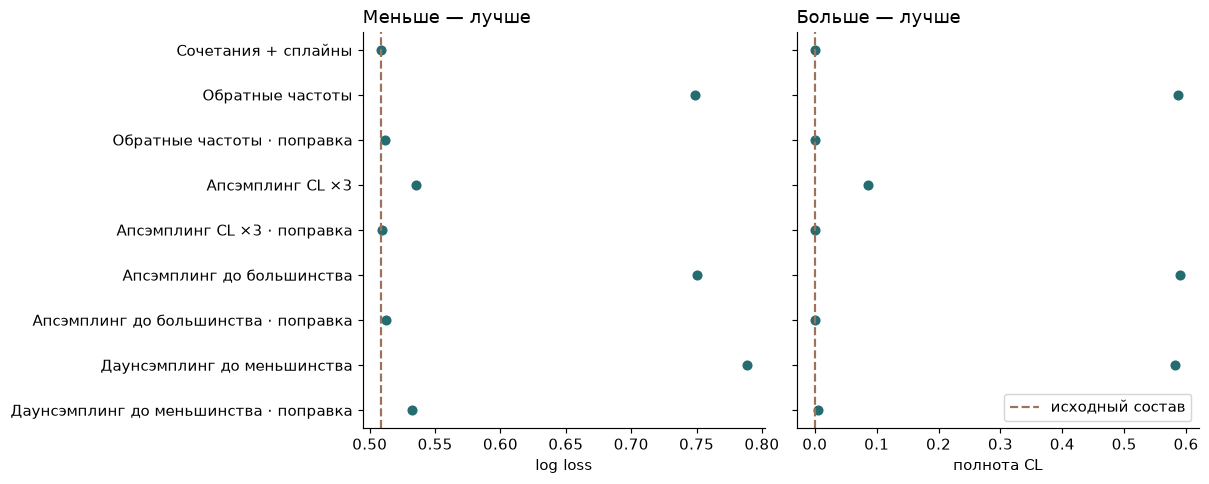

In [10]:
class PriorAdjustedClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator).fit(X, y)
        self.classes_ = self.estimator_.classes_
        target = np.asarray(y)
        def shares(values):
            return pd.Series(values).value_counts(normalize=True).reindex(self.classes_).to_numpy()
        sampler = self.estimator_.named_steps["sample"]
        if hasattr(sampler, "sample_indices_"):
            after = shares(target[sampler.sample_indices_])
        else:
            assert self.estimator_.named_steps["model"].class_weight == "balanced"
            after = np.full(len(self.classes_), 1/len(self.classes_))
        self.ratio_ = shares(target) / after
        return self

    def predict_proba(self, X):
        adjusted = self.estimator_.predict_proba(X) * self.ratio_
        return adjusted / adjusted.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

balance_runs = [linear_name]
for mode, name in balance_names.items():
    if mode == "natural":
        continue
    pipe = make_model(recipe=linear_key, scale=scale_key, balance=mode)
    balance_runs.append(run(name, pipe))
    balance_runs.append(run(name + " · поправка", PriorAdjustedClassifier(pipe)))
balance_scores = summary(balance_runs)
display(balance_scores.round(4))
fig, (ax, bx) = plt.subplots(1,2, figsize=(11.4,4.5), sharey=True, layout="constrained")
positions = np.arange(len(balance_runs))
for i, column in enumerate(["log loss","полнота CL"]):
    target_ax = (ax, bx)[i]
    target_ax.scatter(balance_scores[column], positions, color="#256c70", s=35)
    target_ax.axvline(balance_scores.loc[linear_name,column], color="#9d725b", linestyle="--",
                      label="исходный состав")
    target_ax.set(xlabel=column, yticks=positions, yticklabels=balance_runs,
                  title=("Меньше — лучше" if i == 0 else "Больше — лучше"))
ax.invert_yaxis()
bx.legend(loc="lower right")
plt.show()

In [11]:
best_loss = best(balance_runs)
best_recall = balance_scores["полнота CL"].idxmax()
base_row = balance_scores.loc[linear_name]
down_row = balance_scores.loc[balance_names["down"]]
display(Markdown(f"Без балансировки полнота CL равна **{base_row['полнота CL']:.1%}**, "
                 f"log loss — **{base_row['log loss']:.4f}**. Наибольшая полнота среди этих вариантов "
                 f"у **{best_recall}** ({balance_scores.loc[best_recall,'полнота CL']:.1%}). "
                 f"Полный даунсэмплинг изменил log loss на {down_row['log loss']-base_row['log loss']:+.4f}. "
                 f"По основной метрике в этом сравнении лидирует **{best_loss}**. Столбец средней P(CL) "
                 f"можно сопоставить с естественной долей на разработке ({y.eq('CL').mean():.1%})."))

Без балансировки полнота CL равна **0.0%**, log loss — **0.5086**. Наибольшая полнота среди этих вариантов у **Апсэмплинг до большинства** (59.1%). Полный даунсэмплинг изменил log loss на +0.2797. По основной метрике в этом сравнении лидирует **Сочетания + сплайны**. Столбец средней P(CL) можно сопоставить с естественной долей на разработке (3.5%).

## 4. Может ли нелинейная модель улучшить вероятности

### 4.1. Сначала меняем семейство модели

Гистограммный градиентный бустинг последовательно строит небольшие деревья, которые уточняют прогноз предыдущих. Так он может сам подобрать пороги и взаимодействия. Сравним базовый бустинг на исходных измерениях и на наборе с логарифмами и ручными сочетаниями. Полный даунсэмплинг здесь не является обязательным условием. Бустинг получает обучающие фолды в их естественном составе и без масштабирования.

In [12]:
tree_recipes = {"raw":"Бустинг · исходные", "both":"Бустинг · сочетания"}
for key, name in tree_recipes.items():
    run(name, make_model(kind="tree", recipe=key, scale="none"))
tree_start = best(tree_recipes.values())
tree_key = next(k for k,v in tree_recipes.items() if v == tree_start)
display(summary([linear_name,best_loss,*tree_recipes.values()]).round(4))
tree_change = summary(tree_recipes.values()).loc[tree_recipes["both"],"log loss"] - summary(tree_recipes.values()).loc[tree_recipes["raw"],"log loss"]
display(Markdown(f"У бустинга разница между добавленными сочетаниями и исходными значениями "
                 f"составила {tree_change:+.4f}. Параметры будем подбирать для варианта **{tree_start}**. "
                 "Результат этой пары показывает, понадобились ли деревьям те же преобразования, что и линейной модели."))

,log loss,SD log loss,macro-F1,полнота CL,точность CL,AP CL,средняя P(CL)
Сочетания + сплайны,0.5086,0.0113,0.5291,0.0000,0.0000,0.1491,0.0347
Бустинг · исходные,0.4747,0.0066,0.6277,0.1773,0.4825,0.2698,0.0298
Бустинг · сочетания,0.4772,0.0068,0.6122,0.1455,0.4487,0.2710,0.0296


У бустинга разница между добавленными сочетаниями и исходными значениями составила +0.0025. Параметры будем подбирать для варианта **Бустинг · исходные**. Результат этой пары показывает, понадобились ли деревьям те же преобразования, что и линейной модели.

### 4.2. Сетка и байесовский поиск с равным числом попыток

Скорость обучения задаёт размер шага каждого дерева, число листьев ограничивает сложность, L2 сглаживает оценку в листе. Дадим каждому поиску восемь попыток по пять фолдов. Сетка перебирает восемь заранее заданных комбинаций. Optuna с TPE начинает с трёх случайных попыток, затем использует предыдущие результаты для выбора следующих точек в более широких диапазонах. Одинаковый бюджет даёт сравнимое число обучений. Одна реализация поиска не определяет, какой метод лучше на других задачах.

In [13]:
tree = candidates[tree_start]
grid_space = {"model__learning_rate":[.055,.11], "model__max_leaf_nodes":[7,15],
              "model__l2_regularization":[1.,6.]}
grid_search = GridSearchCV(tree, grid_space, cv=folds, scoring="neg_log_loss",
                           refit=False, error_score="raise", n_jobs=1)
grid_search.fit(X, y)

def objective(trial):
    params = {"model__learning_rate":trial.suggest_float("model__learning_rate", .035, .15, log=True),
              "model__max_leaf_nodes":trial.suggest_int("model__max_leaf_nodes", 6, 24),
              "model__l2_regularization":trial.suggest_float("model__l2_regularization", .3, 10., log=True)}
    candidate = clone(tree).set_params(**params)
    scores = cross_val_score(candidate, X, y, scoring="neg_log_loss", cv=folds, n_jobs=1, error_score="raise")
    return -scores.mean()

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=3))
study.optimize(objective, n_trials=8)
searches = {"Бустинг · сетка":grid_search.best_params_, "Бустинг · Optuna TPE":study.best_params}
search_names = [run(name, clone(tree).set_params(**params)) for name, params in searches.items()]
trials = pd.DataFrame([{"метод":name, "попыток":8, "обучений поиска":8*len(folds),
                        **{k.removeprefix("model__"):v for k,v in params.items()}}
                       for name,params in searches.items()]).set_index("метод")
tuning = summary([tree_start,*search_names])[["log loss","SD log loss"]]
tuning["Δ к бустингу до подбора"] = tuning["log loss"] - tuning.loc[tree_start,"log loss"]
display(trials.round(4))
display(tuning.round(4))
assert np.isclose(tuning.loc["Бустинг · сетка","log loss"], -grid_search.best_score_)
assert np.isclose(tuning.loc["Бустинг · Optuna TPE","log loss"], study.best_value)
search_best = best(search_names)
display(Markdown(f"Лучший из двух поисков в этом запуске — **{search_best}**, "
                 f"разница с бустингом до подбора {tuning.loc[search_best,'Δ к бустингу до подбора']:+.4f}. "
                 "В итоговый отбор также входит исходный бустинг: подбор не обязан его улучшать."))

,попыток,обучений поиска,l2_regularization,learning_rate,max_leaf_nodes
метод,,,,,
Бустинг · сетка,8,40,6.0000,0.1100,7
Бустинг · Optuna TPE,8,40,0.7817,0.0373,16


,log loss,SD log loss,Δ к бустингу до подбора
Бустинг · исходные,0.4747,0.0066,0.0000
Бустинг · сетка,0.4676,0.0019,-0.0072
Бустинг · Optuna TPE,0.4709,0.0073,-0.0038


Лучший из двух поисков в этом запуске — **Бустинг · сетка**, разница с бустингом до подбора -0.0072. В итоговый отбор также входит исходный бустинг: подбор не обязан его улучшать.

### 4.3. Фиксируем рецепт до открытия контроля

Из всех проверенных вариантов с 17 исходными полями выбираем рецепт с минимальным средним log loss. Для краткости в сводке показаны отправные точки и лидеры этапов. Оценки CV использовались для выбора, поэтому результат победителя может быть оптимистичен. Ниже его ждёт отдельная проверка на отложенных строках.

In [14]:
winner = best(list(candidates))
shortlist = list(dict.fromkeys([dummy,scale_name,linear_name,best_loss,tree_start,*search_names,winner]))
leaders = summary(shortlist).sort_values("log loss")
display(leaders.round(4))
losses = results[winner]["folds"]["log loss"]
print(f"Зафиксирован рецепт: {winner} · среднее {losses.mean():.4f} · SD {losses.std():.4f}.")
display(losses.rename("log loss выбранной модели").rename_axis("фолд").round(4).to_frame())

,log loss,SD log loss,macro-F1,полнота CL,точность CL,AP CL,средняя P(CL)
Бустинг · сетка,0.4676,0.0019,0.6131,0.1500,0.4966,0.2678,0.0335
Бустинг · Optuna TPE,0.4709,0.0073,0.6094,0.1409,0.4393,0.2646,0.0314
Бустинг · исходные,0.4747,0.0066,0.6277,0.1773,0.4825,0.2698,0.0298
Сочетания + сплайны,0.5086,0.0113,0.5291,0.0000,0.0000,0.1491,0.0347
MinMaxScaler,0.5326,0.0138,0.5190,0.0000,0.0000,0.1162,0.0347
Частоты классов,0.7755,0.0002,0.2572,0.0000,0.0000,0.0348,0.0348


Зафиксирован рецепт: Бустинг · сетка · среднее 0.4676 · SD 0.0019.


,log loss выбранной модели
фолд,
1,0.4699
2,0.4672
3,0.4684
4,0.4675
5,0.4648


## 5. Как выбрать метку для редкого класса

Соревнованию нужны вероятности, но при разборе ошибок полезно уметь назначать метку `CL`. Если требовать, чтобы вероятность `CL` была выше обеих остальных, многие трансплантации останутся незамеченными. Возьмём OOF-вероятности выбранного рецепта и подберём порог по максимуму F1 класса `CL` — гармонического среднего его точности и полноты. При равенстве выбираем больший порог. Ниже порога присваиваем более вероятный из `C` и `D`. Этот порог служит для учебного сравнения правил решения.

,помечено CL,найдено CL,точность CL,полнота CL,F1 CL,macro-F1,log loss
Максимум вероятности,67,33,0.4925,0.1500,0.2300,0.6145,0.4676
Порог для CL,256,82,0.3203,0.3727,0.3445,0.6503,0.4676


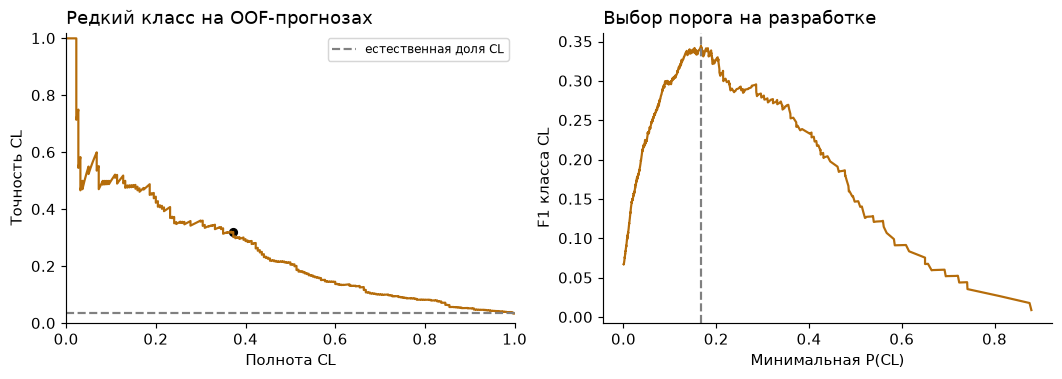

Порог **0.167** фиксируем до контроля. Число помеченных строк на разработке — 256. Найдено 82 из 220 записей с трансплантацией. Вероятности остаются теми же, поэтому log loss в двух строках одинаков.

In [15]:
oof = results[winner]["oof"]
precision, recall, thresholds = precision_recall_curve(y.eq("CL"), oof[:,cl_index])
f1_curve = 2*precision[:-1]*recall[:-1] / np.maximum(precision[:-1]+recall[:-1], 1e-15)
threshold = float(thresholds[np.flatnonzero(f1_curve == f1_curve.max())[-1]])

def rule_table(actual, probabilities):
    rows = {}
    for name, cutoff in [("Максимум вероятности",None), ("Порог для CL",threshold)]:
        pred = decisions(probabilities, cutoff)
        row = metrics(actual, probabilities, pred)
        row["помечено CL"] = int((pred == "CL").sum())
        row["найдено CL"] = int(((pred == "CL") & (np.asarray(actual) == "CL")).sum())
        row["F1 CL"] = f1_score(np.asarray(actual) == "CL", pred == "CL", zero_division=0)
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")[["помечено CL","найдено CL","точность CL","полнота CL","F1 CL","macro-F1","log loss"]]

oof_rules = rule_table(y, oof)
display(oof_rules.round(4))
fig, (ax, bx) = plt.subplots(1,2,figsize=(10,3.5),layout="constrained")
ax.plot(recall, precision, color=COLORS["CL"])
ax.axhline(y.eq("CL").mean(), color="grey", linestyle="--", label="естественная доля CL")
ax.scatter(oof_rules.loc["Порог для CL","полнота CL"], oof_rules.loc["Порог для CL","точность CL"], color="black", s=28)
ax.set(xlabel="Полнота CL", ylabel="Точность CL", title="Редкий класс на OOF-прогнозах", xlim=(0,1), ylim=(0,1.02))
ax.legend(fontsize=8)
bx.plot(thresholds, f1_curve, color=COLORS["CL"])
bx.axvline(threshold, color="grey", linestyle="--")
bx.set(xlabel="Минимальная P(CL)", ylabel="F1 класса CL", title="Выбор порога на разработке")
plt.show()
display(Markdown(f"Порог **{threshold:.3f}** фиксируем до контроля. Число помеченных строк на разработке — "
                 f"{int(oof_rules.loc['Порог для CL','помечено CL'])}. Найдено "
                 f"{int(oof_rules.loc['Порог для CL','найдено CL'])} из {y.eq('CL').sum()} записей с трансплантацией. "
                 "Вероятности остаются теми же, поэтому log loss в двух строках одинаков."))

## 6. Один контроль после выбора модели и порога

### 6.1. Общая потеря и ошибки по каждому исходу

Обучаем зафиксированный рецепт на всей разработке и открываем отложенные метки. Здесь же оцениваем заранее заданную частотную модель. Для неопределённости log loss используем 1000 бутстрэп-выборок контрольных профилей с возвращением. Строки одной группы попадают в повторную выборку вместе. Интервал описывает разброс проверки при фиксированной обученной модели.

In [16]:
X_hold, y_hold = control[PROFILE], control.Status
fitted = clone(candidates[winner]).fit(X, y)
assert list(fitted.classes_) == CLASSES
p_hold = fitted.predict_proba(X_hold)
prior_model = clone(candidates[dummy]).fit(X,y)
p_dummy_hold = prior_model.predict_proba(X_hold)
hold_scores = pd.DataFrame([metrics(y_hold, p_dummy_hold), metrics(y_hold, p_hold)], index=[dummy,winner])
display(hold_scores.round(4))
actual_codes = pd.Categorical(y_hold, categories=CLASSES).codes
row_losses = -np.log(np.clip(p_hold[np.arange(len(y_hold)),actual_codes], np.finfo(float).eps, 1))
g = profile_ids(control)
loss_by_group = np.bincount(g, weights=row_losses)
size_by_group = np.bincount(g)
rng = np.random.default_rng(SEED)
bootstrap = []
for _ in range(1000):
    sample_groups = rng.integers(0, len(size_by_group), size=len(size_by_group))
    bootstrap.append(loss_by_group[sample_groups].sum() / size_by_group[sample_groups].sum())
lo, hi = np.quantile(bootstrap, [.025,.975])
hold_loss = hold_scores.loc[winner,"log loss"]
hold_gain = hold_scores.loc[dummy,"log loss"] - hold_loss
assert np.isclose(row_losses.mean(), hold_loss)
hold_rules = rule_table(y_hold, p_hold)
display(hold_rules.round(4))
report = pd.DataFrame(classification_report(y_hold, decisions(p_hold), labels=CLASSES,
                                            output_dict=True, zero_division=0)).T.loc[CLASSES]
display(report.rename(columns={"precision":"точность","recall":"полнота","f1-score":"F1","support":"строк"}).round(3))
display(Markdown(f"Размер контрольной выборки — {len(control)}. Log loss равен **{hold_loss:.4f}**, "
                 f"95%-й бутстрэп-интервал **[{lo:.4f}, {hi:.4f}]**. Снижение относительно прогноза по "
                 f"частотам на тех же строках — **{hold_gain:.4f}**. Число записей CL в контроле — {y_hold.eq('CL').sum()}. "
                 "Поэтому несколько пропущенных или найденных трансплантаций ощутимо меняют оценку полноты."))

,log loss,macro-F1,полнота CL,точность CL,AP CL,средняя P(CL)
Частоты классов,0.7755,0.2572,0.0000,0.0,0.0348,0.0348
Бустинг · сетка,0.4600,0.6677,0.2727,0.6,0.3555,0.0379


,помечено CL,найдено CL,точность CL,полнота CL,F1 CL,macro-F1,log loss
Максимум вероятности,25,15,0.6000,0.2727,0.3750,0.6677,0.46
Порог для CL,82,27,0.3293,0.4909,0.3942,0.6676,0.46


,точность,полнота,F1,строк
C,0.838,0.908,0.872,993.0
CL,0.600,0.273,0.375,55.0
D,0.798,0.719,0.756,533.0


Размер контрольной выборки — 1581. Log loss равен **0.4600**, 95%-й бутстрэп-интервал **[0.4232, 0.4976]**. Снижение относительно прогноза по частотам на тех же строках — **0.3155**. Число записей CL в контроле — 55. Поэтому несколько пропущенных или найденных трансплантаций ощутимо меняют оценку полноты.

### 6.2. Почему средняя потеря на контроле отличается от OOF

Общий log loss растёт как при увеличении доли сложного класса, так и при ухудшении прогноза внутри класса. Разложим разницу на эти части. Сначала мысленно оставим средние ошибки OOF внутри каждого класса и заменим только частоты классов на контрольные. Затем подставим и контрольные ошибки. Для этого расчёта каждую строку разработки учитываем один раз.

In [17]:
oof_codes = pd.Categorical(y, categories=CLASSES).codes
oof_losses = -np.log(np.clip(oof[np.arange(len(y)),oof_codes], np.finfo(float).eps, 1))
class_loss = pd.DataFrame({
    "доля OOF":y.value_counts(normalize=True), "доля контроля":y_hold.value_counts(normalize=True),
    "потеря OOF":pd.Series(oof_losses).groupby(y).mean(),
    "потеря контроля":pd.Series(row_losses).groupby(y_hold).mean(),
}).reindex(CLASSES)
mix_effect = ((class_loss["доля контроля"]-class_loss["доля OOF"])*class_loss["потеря OOF"]).sum()
within_effect = (class_loss["доля контроля"]*(class_loss["потеря контроля"]-class_loss["потеря OOF"])).sum()
assert np.isclose(mix_effect + within_effect, hold_loss - oof_losses.mean())
display(class_loss.round(4))
display(Markdown(f"Полная разница с объединёнными OOF-прогнозами — **{hold_loss-oof_losses.mean():+.4f}**. "
                 f"Замена долей классов даёт **{mix_effect:+.4f}**, изменение средних ошибок внутри "
                 f"классов — ещё **{within_effect:+.4f}**. Это арифметический разбор расхождения "
                 "на одной выборке. Он не устанавливает причину ошибок отдельных пациентов."))

,доля OOF,доля контроля,потеря OOF,потеря контроля
Status,,,,
C,0.6281,0.6281,0.2748,0.2714
CL,0.0348,0.0348,2.6280,2.3610
D,0.3371,0.3371,0.6037,0.6152


Полная разница с объединёнными OOF-прогнозами — **-0.0076**. Замена долей классов даёт **+0.0000**, изменение средних ошибок внутри классов — ещё **-0.0076**. Это арифметический разбор расхождения на одной выборке. Он не устанавливает причину ошибок отдельных пациентов.

### 6.3. Какую цену платим за дополнительные находки

Две матрицы ниже используют одни и те же вероятности. Строка — фактический исход, столбец — назначенная метка. Рост числа найденных трансплантаций стоит читать вместе с числом ошибочных пометок `CL` у исходов `C` и `D`.

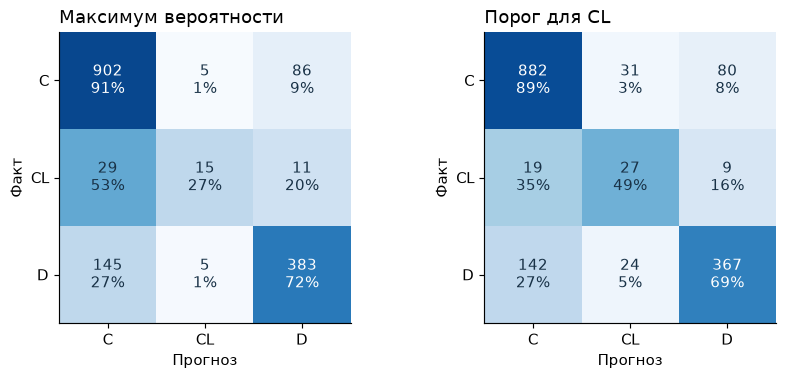

Переход к порогу изменил число найденных CL с **15** до **27**. Число ложных пометок CL изменилось с **10** до **55**. Это отдельный выбор между полнотой и точностью. В submission остаются исходные вероятности.

In [18]:
fig, axes = plt.subplots(1,2,figsize=(8.1,3.5),layout="constrained")
for ax, cutoff, name in zip(axes, [None,threshold], ["Максимум вероятности","Порог для CL"]):
    cm = confusion_matrix(y_hold, decisions(p_hold,cutoff), labels=CLASSES)
    shares = cm / cm.sum(axis=1,keepdims=True)
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    for i,j in np.ndindex(cm.shape):
        ax.text(j,i,f"{cm[i,j]}\n{shares[i,j]:.0%}",ha="center",va="center",
                color="white" if shares[i,j]>.55 else "#193247")
    ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel="Прогноз", ylabel="Факт", title=name)
plt.show()
a, b = hold_rules.loc["Максимум вероятности"], hold_rules.loc["Порог для CL"]
display(Markdown(f"Переход к порогу изменил число найденных CL с **{int(a['найдено CL'])}** до "
                 f"**{int(b['найдено CL'])}**. Число ложных пометок CL изменилось с "
                 f"**{int(a['помечено CL']-a['найдено CL'])}** до **{int(b['помечено CL']-b['найдено CL'])}**. "
                 "Это отдельный выбор между полнотой и точностью. В submission остаются исходные вероятности."))

### 6.4. Соответствует ли вероятность CL наблюдаемой частоте

Разделим контрольные прогнозы на шесть равных по числу строк групп по возрастанию `P(CL)`. Для каждой группы сравним средний прогноз с фактической долей трансплантаций. Полезное ранжирование и хорошее совпадение вероятностей с частотами — разные свойства модели.

,строк,трансплантаций,прогноз,частота
от меньшей P(CL),,,,
0,264,2,0.0021,0.0076
1,263,0,0.0048,0.0000
2,264,5,0.0086,0.0189
3,263,6,0.0152,0.0228
4,263,6,0.0308,0.0228
5,264,36,0.1659,0.1364


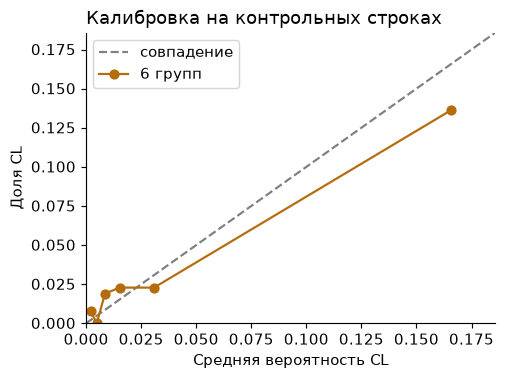

В верхней шестой части по P(CL) средний прогноз — **16.6%**, наблюдаемая частота — **13.6%** (36 из 264). В каждой группе мало редких событий, поэтому отдельные отклонения от диагонали следует трактовать осторожно.

In [19]:
cal = pd.DataFrame({"p":p_hold[:,cl_index], "CL":y_hold.eq("CL").astype(int).to_numpy()})
cal["группа"] = pd.qcut(cal.p, q=6, duplicates="drop")
reliability = cal.groupby("группа", observed=True).agg(
    строк=("CL","size"), трансплантаций=("CL","sum"), прогноз=("p","mean"), частота=("CL","mean"))
display(reliability.reset_index(drop=True).rename_axis("от меньшей P(CL)").round(4))
fig, ax = plt.subplots(figsize=(4.7,3.5), layout="constrained")
upper = max(reliability.прогноз.max(), reliability.частота.max())*1.12
ax.plot([0,upper], [0,upper], "--", color="grey", label="совпадение")
ax.plot(reliability.прогноз, reliability.частота, "o-", color=COLORS["CL"], label="6 групп")
ax.set(xlim=(0,upper), ylim=(0,upper), xlabel="Средняя вероятность CL", ylabel="Доля CL",
       title="Калибровка на контрольных строках")
ax.legend()
plt.show()
top_bin = reliability.iloc[-1]
display(Markdown(f"В верхней шестой части по P(CL) средний прогноз — **{top_bin.прогноз:.1%}**, "
                 f"наблюдаемая частота — **{top_bin.частота:.1%}** ({int(top_bin.трансплантаций)} "
                 f"из {int(top_bin.строк)}). В каждой группе мало редких событий, "
                 "поэтому отдельные отклонения от диагонали следует трактовать осторожно."))

### 6.5. На какие исходные поля опирается прогноз

Перемешаем каждое исходное поле между контрольными записями четыре раза, не переобучая модель. Пайплайн заново пересчитает и все производные этого поля. Прирост log loss покажет, какие измерения помогают уже выбранному рецепту. При коррелирующих измерениях часть сигнала может оставаться во втором признаке. Разброс здесь относится к четырём перемешиваниям.

In [20]:
perm = permutation_importance(fitted, X_hold, y_hold, scoring="neg_log_loss",
                              n_repeats=4, random_state=SEED, n_jobs=1)
importance = pd.DataFrame({"рост log loss":perm.importances_mean, "SD перестановок":perm.importances_std},
                          index=PROFILE).sort_values("рост log loss", ascending=False)
display(importance.head(8).round(4))
first, second = importance.index[:2]
display(Markdown(f"Самые заметные изменения дали **{first}** и **{second}**. Перемешивание {first} "
                 f"увеличило потерю в среднем на {importance.iloc[0,0]:.4f}. Эти числа описывают "
                 "поведение модели на синтетических строках и не устанавливают причинных эффектов."))

,рост log loss,SD перестановок
Bilirubin,0.0762,0.0101
Age,0.0384,0.0064
Prothrombin,0.0329,0.0027
SGOT,0.0272,0.0017
Copper,0.0208,0.0035
Platelets,0.0151,0.0018
Alk_Phos,0.0119,0.0037
Edema,0.0112,0.0021


Самые заметные изменения дали **Bilirubin** и **Age**. Перемешивание Bilirubin увеличило потерю в среднем на 0.0762. Эти числа описывают поведение модели на синтетических строках и не устанавливают причинных эффектов.

## 7. Прогноз для конкурсного файла

После контрольной оценки переобучаем выбранный рецепт на всех 7 905 размеченных строках. Имена вероятностей берём из `classes_` модели и выстраиваем по образцу соревнования. Проверяем идентификаторы, диапазон, сумму каждой строки и повторное чтение сохранённого CSV.

In [21]:
final_model = clone(candidates[winner]).fit(train[PROFILE], train.Status)
p_test = final_model.predict_proba(test[PROFILE])
probs = pd.DataFrame(p_test, columns=[f"Status_{c}" for c in final_model.classes_])
submission = pd.concat([test[["id"]].reset_index(drop=True), probs], axis=1)[template.columns]
prob_cols = [f"Status_{c}" for c in CLASSES]
def validate_submission(frame):
    assert frame.shape == template.shape and list(frame.columns) == list(template.columns)
    assert frame.id.is_unique and frame.id.equals(template.id)
    values = frame[prob_cols].to_numpy()
    assert np.isfinite(values).all() and ((values >= 0) & (values <= 1)).all()
    assert np.allclose(values.sum(axis=1), 1, rtol=0, atol=1e-10)

validate_submission(submission)
output = Path("submission.csv")
submission.to_csv(output, index=False)
saved = pd.read_csv(output)
validate_submission(saved)
assert np.allclose(saved[prob_cols], probs[prob_cols], rtol=0, atol=1e-12)
print(f"{output.name} · {len(saved)} строк · {', '.join(saved.columns)}")
display(saved.head(4))

submission.csv · 5271 строк · id, Status_C, Status_CL, Status_D


,id,Status_C,Status_CL,Status_D
0,7905,0.735479,0.011099,0.253422
1,7906,0.679974,0.104412,0.215614
2,7907,0.045634,0.003947,0.950420
3,7908,0.951712,0.004717,0.043571


## 8. Что показал эксперимент

In [22]:
display(Markdown(
    f"Для вероятностного прогноза выбран **{winner}**. На пяти групповых фолдах log loss равен "
    f"**{losses.mean():.4f} ± {losses.std():.4f}** (среднее ± SD), на контроле — **{hold_loss:.4f}**. "
    f"У частотной модели на контроле — {hold_scores.loc[dummy,'log loss']:.4f}.\n\n"
    f"В экспериментах с составом обучения наибольшую полноту CL дал вариант **{best_recall}**, "
    f"а наименьшую потерю — **{best_loss}**. Это разные критерии успеха. "
    f"У выбранной итоговой модели порог {threshold:.3f} дал на контроле полноту CL "
    f"**{b['полнота CL']:.1%}** при точности **{b['точность CL']:.1%}**. "
    "Так можно явно обсудить цену ложных сигналов, сохраняя исходные вероятности для Kaggle."
))

Для вероятностного прогноза выбран **Бустинг · сетка**. На пяти групповых фолдах log loss равен **0.4676 ± 0.0019** (среднее ± SD), на контроле — **0.4600**. У частотной модели на контроле — 0.7755.

В экспериментах с составом обучения наибольшую полноту CL дал вариант **Апсэмплинг до большинства**, а наименьшую потерю — **Сочетания + сплайны**. Это разные критерии успеха. У выбранной итоговой модели порог 0.167 дал на контроле полноту CL **49.1%** при точности **32.9%**. Так можно явно обсудить цену ложных сигналов, сохраняя исходные вероятности для Kaggle.

Итоговый контроль был отложен до экспериментов этой версии. Оба исходных EDA уже описывали полный размеченный файл, а все строки происходят из одного синтетического набора. Следовательно, это внутренняя проверка. Перенос на реальных пациентов, на другой период наблюдения или на другую клинику потребовал бы отдельной размеченной выборки. У конкурсного test метки скрыты, и его log loss здесь неизвестен.